In [2]:
import seaborn as sns 
# Load the 'taxis' dataset 
df = sns.load_dataset("taxis")

In [4]:
# Check the number of missing values in each column
print(df.isnull().sum())


pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [5]:
# Display columns that contain missing values
missing_values = df.isnull().sum()

print("Columns with missing values:")
print(missing_values[missing_values > 0])

Columns with missing values:
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [7]:
import pandas as pd

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)



In [7]:
# Fill missing categorical values using mode

categorical_cols = ['payment', 'pickup_zone', 'dropoff_zone',
                    'pickup_borough', 'dropoff_borough']

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# Check missing values after imputation
print(df.isnull().sum())

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


In [15]:
# Fill missing numerical values using median

numerical_cols = df.select_dtypes(include=['number']).columns

for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())
    print(df.isnull().sum())

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64
pickup             0
dropoff            0
passengers         0
distance        

In [8]:
# Identify critical columns
critical_cols = ['pickup', 'dropoff']

# Remove rows with missing values in critical columns
df.dropna(subset=critical_cols, inplace=True)

# Display the updated dataset
#print(df)

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_23608\2333958591.py:5: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(subset=critical_cols, inplace=True)


In [9]:
import matplotlib.pyplot as plt
import pandas as pd

In [10]:
df['pickup'] = pd.to_datetime(df['pickup'])
df = df.sort_values(by='pickup')


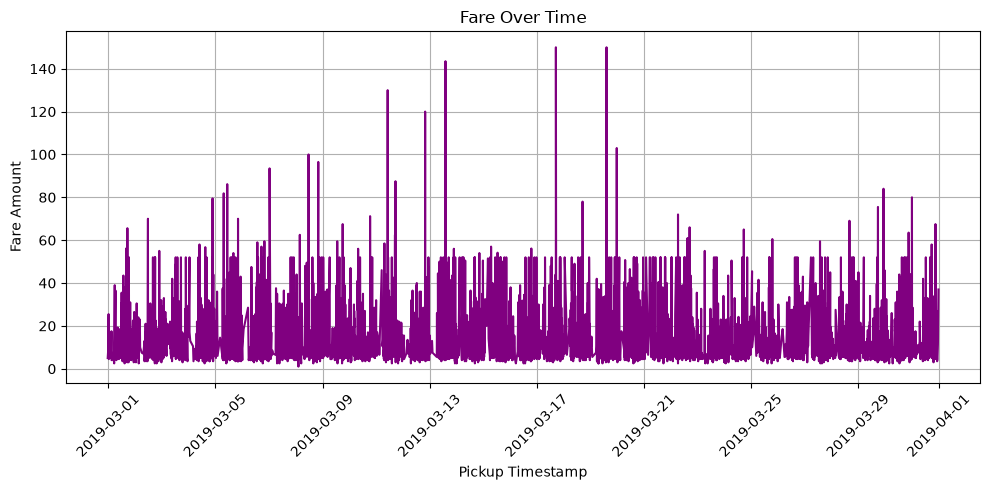

In [33]:
# Plot fare over time 
# Line Chart
plt.figure(figsize=(10, 5))

plt.plot(df['pickup'], df['fare'], color='Purple')

plt.title('Fare Over Time')
plt.xlabel('Pickup Timestamp')
plt.ylabel('Fare Amount')

plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

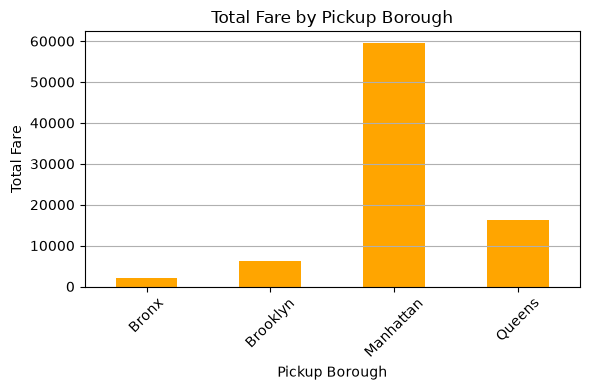

In [15]:
#Bar Chart
borough_fare = df.groupby('pickup_borough')['fare'].sum()
# Plot total fare for each pickup borough
plt.figure(figsize=(6, 4))

borough_fare.plot(kind='bar', color='orange')

plt.title('Total Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')

plt.xticks(rotation=45)
plt.grid(axis='y')

plt.tight_layout()
plt.show()

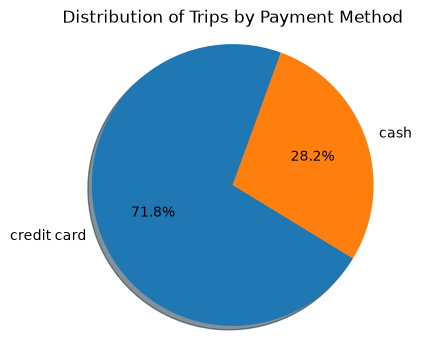

In [21]:
#Pie Chart
payment_counts = df['payment'].value_counts()
# Plot pie chart
plt.figure(figsize=(4, 4))

plt.pie(payment_counts,
        labels=payment_counts.index,
        autopct='%1.1f%%',
        startangle=70,
        shadow=True)

plt.title('Distribution of Trips by Payment Method')

plt.axis('equal')
plt.show()

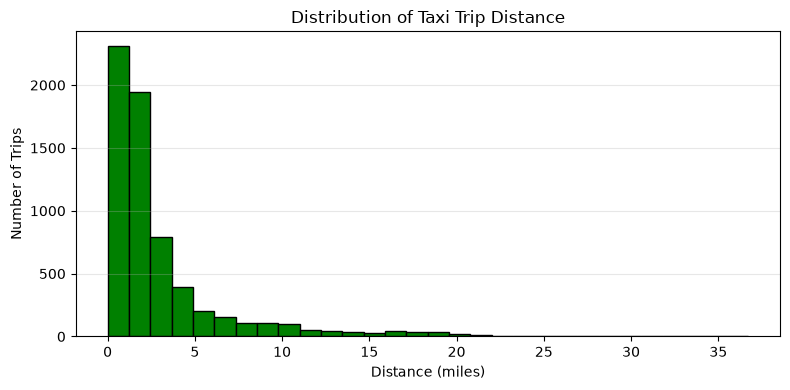

In [27]:
#Histogram

plt.figure(figsize=(8, 4))

plt.hist(df['distance'],
         bins=30,
         color='green',
         edgecolor='black')

plt.title('Distribution of Taxi Trip Distance')
plt.xlabel('Distance (miles)')
plt.ylabel('Number of Trips')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

<Figure size 800x600 with 0 Axes>

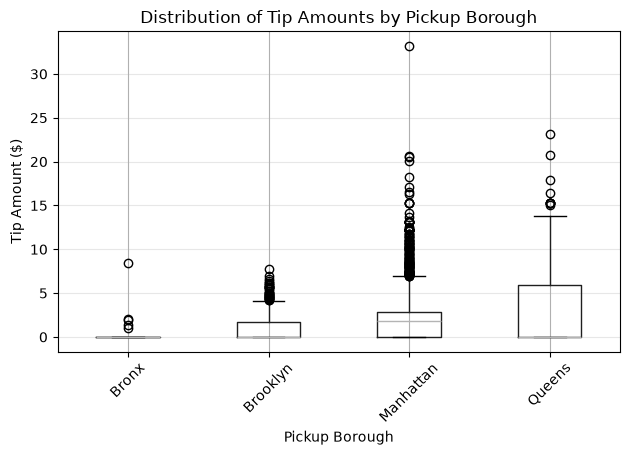

In [32]:
#Box Plot

plt.figure(figsize=(8, 6))

df.boxplot(column='tip', by='pickup_borough')

plt.title('Distribution of Tip Amounts by Pickup Borough')
plt.suptitle('')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount ($)')

plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_4904\784326778.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df,


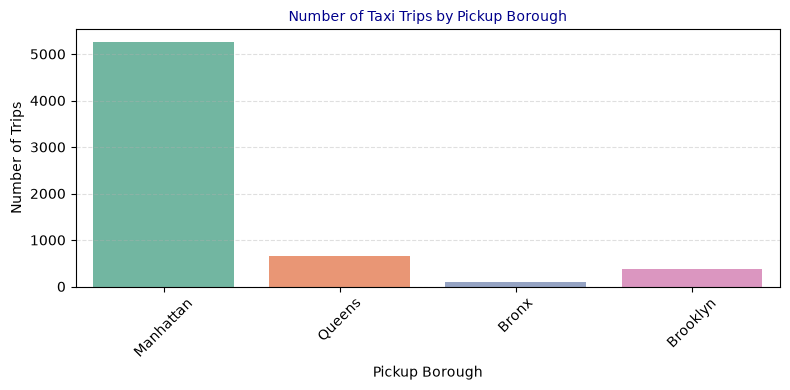

In [6]:
#Count Plot
# Set figure size
plt.figure(figsize=(8, 4))

# Create count plot
sns.countplot(data=df,
              x='pickup_borough',
              palette='Set2')

# Add title and labels
plt.title('Number of Taxi Trips by Pickup Borough',
          fontsize=10, color='darkblue')

plt.xlabel('Pickup Borough')
plt.ylabel('Number of Trips')

plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

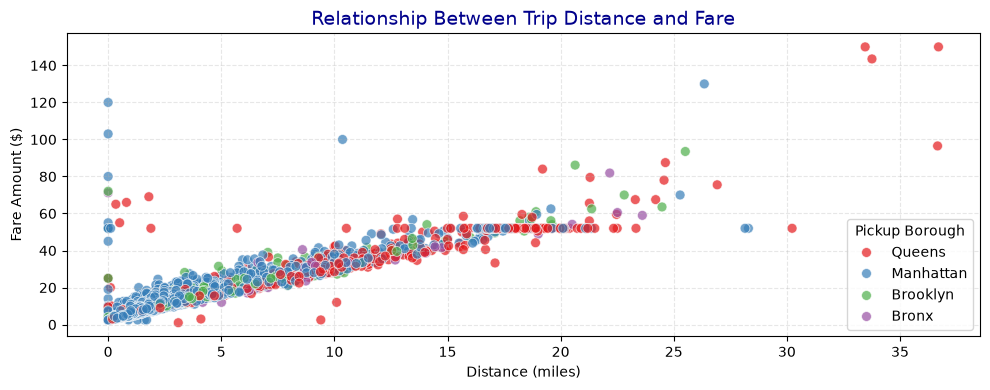

In [41]:
#Scatter Plot
# Set figure size
plt.figure(figsize=(10, 4))

# Create scatter plot
sns.scatterplot(data=df,
                x='distance',
                y='fare',
                hue='pickup_borough',
                palette='Set1',
                alpha=0.7,
                s=50)

# Add title and labels
plt.title('Relationship Between Trip Distance and Fare',
          fontsize=14, color='darkblue')

plt.xlabel('Distance (miles)')
plt.ylabel('Fare Amount ($)')

plt.legend(title='Pickup Borough')
plt.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

          distance      fare       tip     tolls     total
distance  1.000000  0.920108  0.452589  0.635267  0.904676
fare      0.920108  1.000000  0.488612  0.609307  0.974358
tip       0.452589  0.488612  1.000000  0.413619  0.646186
tolls     0.635267  0.609307  0.413619  1.000000  0.683142
total     0.904676  0.974358  0.646186  0.683142  1.000000


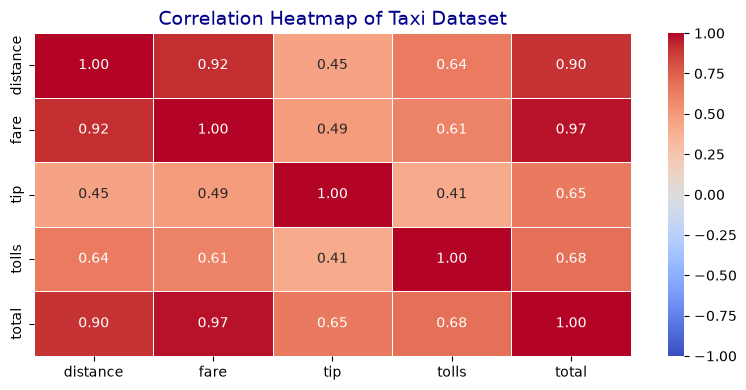

In [44]:
#Heatmap
# Select numerical columns
numerical_data = df[['distance', 'fare', 'tip', 'tolls', 'total']]

# Calculate correlation matrix
correlation_matrix = numerical_data.corr()

# Display correlation matrix
print(correlation_matrix)
# Set figure size
plt.figure(figsize=(8, 4))

# Create heatmap
sns.heatmap(correlation_matrix,
            annot=True,
            cmap='coolwarm',
            linewidths=0.5,
            fmt='.2f',
            vmin=-1,
            vmax=1)

plt.title('Correlation Heatmap of Taxi Dataset',
          fontsize=14, color='darkblue')

plt.tight_layout()
plt.show()

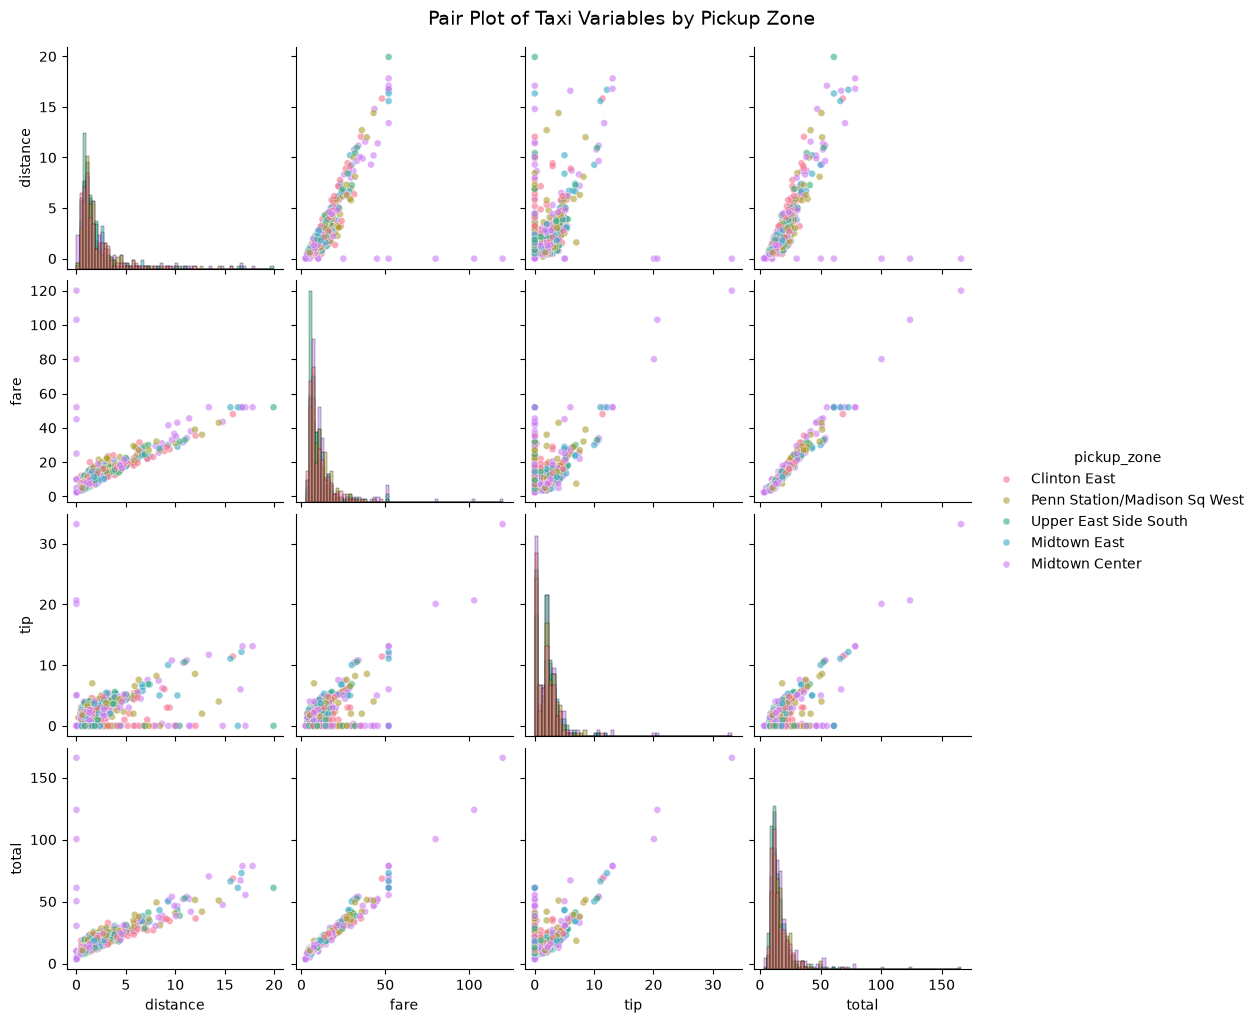

In [19]:
#Pair Plot
# Select required columns
pair_data = df[['distance', 'fare', 'tip', 'total', 'pickup_zone']].dropna()

# Select the top 5 pickup zones
top_zones = pair_data['pickup_zone'].value_counts().head(5).index

pair_data = pair_data[pair_data['pickup_zone'].isin(top_zones)]

# Take a sample of 1000 rows for faster plotting
pair_data = pair_data.sample(n=min(1000, len(pair_data)), random_state=42)

# Create colorful pair plot
sns.pairplot(pair_data,
             vars=['distance', 'fare', 'tip', 'total'],
             hue='pickup_zone',
             palette='husl',
             diag_kind='hist',
             plot_kws={'alpha': 0.6, 's': 25})

plt.suptitle('Pair Plot of Taxi Variables by Pickup Zone',
             y=1.02,
             fontsize=14)

plt.show()

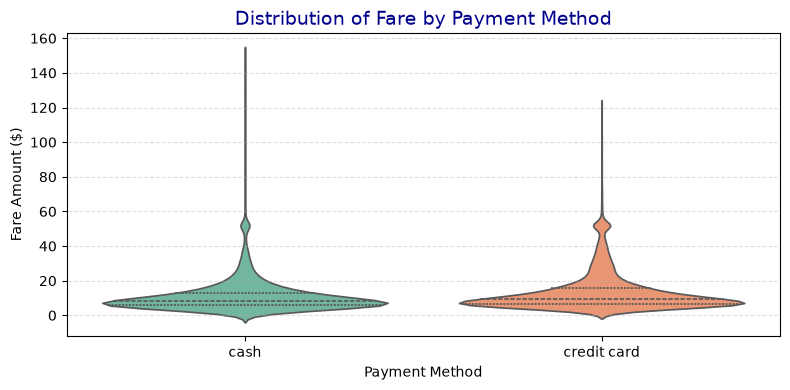

In [17]:
#Violin Plot
# Create colorful violin plot
plt.figure(figsize=(8, 4))

sns.violinplot(data=df,
               x='payment',
               y='fare',
               hue='payment',
               palette='Set2',
               legend=False,
               inner='quartile')

plt.title('Distribution of Fare by Payment Method',
          fontsize=14,
          color='darkblue')

plt.xlabel('Payment Method')
plt.ylabel('Fare Amount ($)')

plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()
